<center><h1>Data Exploration</h1></center>






### Notebook Initialization

In [1]:
print("Welcome to RetailPulse!")

print("My Data Science project")

Welcome to RetailPulse!
My Data Science project


In [3]:
print("RetailPulse - Data Exploration")
print("Step 1: Understanding the dataset")

RetailPulse - Data Exploration
Step 1: Understanding the dataset


### Library Imports and Data Access
#### Import the required libraries and verify the availability of the raw datasets.

### SALES DATA EXPLORATION

In [75]:
import pandas as pd
import os

print("Libraries imported successfully!")

data_folder = "../data/raw"

print("Files available:", os.listdir(data_folder))

df = pd.read_csv("../data/raw/sales_daily.csv")

df.head()

Libraries imported successfully!
Files available: ['calendar.csv', 'inventory_snapshots.csv', 'sales_daily.csv']


,Date,SKU,Units_Sold,Revenue,Price,Promotion
0,2024-01-01,SKU001,5,18320.25,3664.05,0
1,2024-01-01,SKU002,15,57085.35,3805.69,0
2,2024-01-01,SKU003,5,40391.15,8078.23,0
3,2024-01-01,SKU004,5,34307.85,6861.57,0
4,2024-01-01,SKU005,12,113918.64,9493.22,0


### Sales Data Profiling
#### Examine the sales dataset structure, column names, data types, missing values, duplicate records, descriptive statistics, and value distributions.

In [77]:
df.shape

(36550, 6)

In [79]:
df.columns

Index(['Date', 'SKU', 'Units_Sold', 'Revenue', 'Price', 'Promotion'], dtype='object')

In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36550 entries, 0 to 36549
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        36550 non-null  object 
 1   SKU         36550 non-null  object 
 2   Units_Sold  36550 non-null  int64  
 3   Revenue     36550 non-null  float64
 4   Price       36550 non-null  float64
 5   Promotion   36550 non-null  int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 1.7+ MB


In [83]:
df.isnull().sum()

Date          0
SKU           0
Units_Sold    0
Revenue       0
Price         0
Promotion     0
dtype: int64

In [87]:
df.duplicated().sum()

0

In [89]:
df.describe()

,Units_Sold,Revenue,Price,Promotion
count,36550.000000,36550.00000,36550.000000,36550.000000
mean,14.003010,84707.43385,5892.663800,0.102599
std,8.467305,76534.63044,3138.775609,0.303439
min,0.000000,0.00000,663.460000,0.000000
25%,7.000000,27643.70000,3484.090000,0.000000
50%,13.000000,56125.90000,5649.795000,0.000000
75%,20.000000,127954.32000,8516.600000,0.000000
max,56.000000,546977.00000,11642.450000,1.000000


In [93]:
# missing value summary
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary

,Missing_Count,Missing_Percentage
Date,0,0.0
SKU,0,0.0
Units_Sold,0,0.0
Revenue,0,0.0
Price,0,0.0
Promotion,0,0.0


In [95]:
#Inspect Duplicate Records
duplicate_rows = df[df.duplicated()]

duplicate_rows.head()

,Date,SKU,Units_Sold,Revenue,Price,Promotion


In [97]:
# Identify Column Types
df.select_dtypes(include="number").columns.tolist()

['Units_Sold', 'Revenue', 'Price', 'Promotion']

In [99]:
df.select_dtypes(include="object").columns.tolist()

['Date', 'SKU']

In [171]:
# Numerical Summary
df[["Units_Sold", "Revenue", "Price", "Promotion"]].describe()

,Units_Sold,Revenue,Price,Promotion
count,36550.000000,36550.00000,36550.000000,36550.000000
mean,14.003010,84707.43385,5892.663800,0.102599
std,8.467305,76534.63044,3138.775609,0.303439
min,0.000000,0.00000,663.460000,0.000000
25%,7.000000,27643.70000,3484.090000,0.000000
50%,13.000000,56125.90000,5649.795000,0.000000
75%,20.000000,127954.32000,8516.600000,0.000000
max,56.000000,546977.00000,11642.450000,1.000000


In [179]:
# Promotion Distribution

df["Promotion"].value_counts(dropna=False)


Promotion
0    32800
1     3750
Name: count, dtype: int64

### Sales Date and Business Rule Validation

#### Validate the sales date range and identify unusual values in units sold, revenue, price, and promotion fields. Inspect zero-sales records for business interpretation.

In [181]:
# Sales Date and Business Rule Validation
df["Date"] = pd.to_datetime(df["Date"])

print("Sales start:", df["Date"].min())
print("Sales end:", df["Date"].max())
print("Unique sales dates:", df["Date"].nunique())

Sales start: 2024-01-01 00:00:00
Sales end: 2025-12-31 00:00:00
Unique sales dates: 731


### INVENTORY DATA EXPLORATION

#### Assess inventory completeness, SKU coverage, stock quantities, lead times, safety stock, reorder points, and inventory valuation.

In [106]:
# Inventory Data Profiling and Validation
df_inventory = pd.read_csv("../data/raw/inventory_snapshots.csv")

df_inventory.head()

,Snapshot_Date,SKU,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Reorder_Point,Inventory_Value
0,2024-01-01,SKU001,16,23,11,7,18,58420.96
1,2024-01-01,SKU002,29,12,4,5,10,163983.40
2,2024-01-01,SKU003,34,23,14,6,20,209060.22
3,2024-01-01,SKU004,34,4,7,5,12,42257.92
4,2024-01-01,SKU005,23,5,5,6,11,170945.89


In [114]:
df_inventory.shape

(4800, 8)

In [116]:
df_inventory.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4800 entries, 0 to 4799
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Snapshot_Date    4800 non-null   object 
 1   SKU              4800 non-null   object 
 2   Current_Stock    4800 non-null   int64  
 3   On_Order         4800 non-null   int64  
 4   Lead_Time_Days   4800 non-null   int64  
 5   Safety_Stock     4800 non-null   int64  
 6   Reorder_Point    4800 non-null   int64  
 7   Inventory_Value  4800 non-null   float64
dtypes: float64(1), int64(5), object(2)
memory usage: 300.1+ KB


In [122]:
df_inventory.isnull().sum()


Snapshot_Date      0
SKU                0
Current_Stock      0
On_Order           0
Lead_Time_Days     0
Safety_Stock       0
Reorder_Point      0
Inventory_Value    0
dtype: int64

In [124]:
df_inventory.duplicated().sum()

0

In [126]:
df_inventory.describe()

,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Reorder_Point,Inventory_Value
count,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4.800000e+03
mean,304.143333,213.093750,8.438958,83.152708,211.745417,1.304166e+06
std,280.890448,244.456955,3.488024,70.256045,179.905422,1.741551e+06
min,2.000000,0.000000,3.000000,5.000000,10.000000,2.444200e+03
25%,109.000000,49.000000,5.000000,35.000000,87.000000,2.521855e+05
50%,229.000000,135.000000,8.000000,67.000000,169.000000,6.837389e+05
75%,418.000000,292.000000,11.250000,112.000000,286.000000,1.720023e+06
max,2585.000000,3060.000000,14.000000,746.000000,1661.000000,2.027987e+07


In [128]:
# Inspect Snapshot Dates
df_inventory["Snapshot_Date"].head()

0    2024-01-01
1    2024-01-01
2    2024-01-01
3    2024-01-01
4    2024-01-01
Name: Snapshot_Date, dtype: object

In [130]:
# SKU Coverage
df_inventory["SKU"].nunique()

200

In [132]:
df_inventory["SKU"].value_counts().head(10)

SKU
SKU001    24
SKU138    24
SKU128    24
SKU129    24
SKU130    24
SKU131    24
SKU132    24
SKU133    24
SKU134    24
SKU135    24
Name: count, dtype: int64

In [134]:
# Inventory Statistics
df_inventory[
    ["Current_Stock", "On_Order", "Lead_Time_Days",
     "Safety_Stock", "Reorder_Point", "Inventory_Value"]
].describe().round(2)

,Current_Stock,On_Order,Lead_Time_Days,Safety_Stock,Reorder_Point,Inventory_Value
count,4800.00,4800.00,4800.00,4800.00,4800.00,4800.00
mean,304.14,213.09,8.44,83.15,211.75,1304166.47
std,280.89,244.46,3.49,70.26,179.91,1741551.24
min,2.00,0.00,3.00,5.00,10.00,2444.20
25%,109.00,49.00,5.00,35.00,87.00,252185.50
50%,229.00,135.00,8.00,67.00,169.00,683738.86
75%,418.00,292.00,11.25,112.00,286.00,1720023.44
max,2585.00,3060.00,14.00,746.00,1661.00,20279867.85


In [136]:
# Inventory Date Range
df_inventory["Snapshot_Date"] = pd.to_datetime(
    df_inventory["Snapshot_Date"]
)

print("Start date:", df_inventory["Snapshot_Date"].min())
print("End date:", df_inventory["Snapshot_Date"].max())

Start date: 2024-01-01 00:00:00
End date: 2025-12-01 00:00:00


### CALENDAR DATA EXPLORATION

#### Inspect date coverage, missing values, duplicate records, seasonal attributes, holiday indicators, and promotion-event features.

In [140]:
# Calendar Data Profiling and Validation
df_calendar = pd.read_csv("../data/raw/calendar.csv")

df_calendar.head()

,date,year,month,quarter,week,day_of_week,is_weekend,season,holiday,is_holiday,promotion_event
0,2024-01-01,2024,1,Q1,1,Monday,0,Winter,NaN,0,NaN
1,2024-01-02,2024,1,Q1,1,Tuesday,0,Winter,NaN,0,NaN
2,2024-01-03,2024,1,Q1,1,Wednesday,0,Winter,NaN,0,NaN
3,2024-01-04,2024,1,Q1,1,Thursday,0,Winter,NaN,0,NaN
4,2024-01-05,2024,1,Q1,1,Friday,0,Winter,NaN,0,NaN


In [142]:
df_calendar.shape

(731, 11)

In [144]:
df_calendar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   date             731 non-null    object
 1   year             731 non-null    int64 
 2   month            731 non-null    int64 
 3   quarter          731 non-null    object
 4   week             731 non-null    int64 
 5   day_of_week      731 non-null    object
 6   is_weekend       731 non-null    int64 
 7   season           731 non-null    object
 8   holiday          8 non-null      object
 9   is_holiday       731 non-null    int64 
 10  promotion_event  75 non-null     object
dtypes: int64(5), object(6)
memory usage: 62.9+ KB


In [146]:
df_calendar.isnull().sum()

date                 0
year                 0
month                0
quarter              0
week                 0
day_of_week          0
is_weekend           0
season               0
holiday            723
is_holiday           0
promotion_event    656
dtype: int64

In [148]:
df_calendar.duplicated().sum()

0

In [150]:
# Calendar Date Range
df_calendar["date"] = pd.to_datetime(df_calendar["date"])

print("Calendar start:", df_calendar["date"].min())
print("Calendar end:", df_calendar["date"].max())
print("Unique dates:", df_calendar["date"].nunique())

Calendar start: 2024-01-01 00:00:00
Calendar end: 2025-12-31 00:00:00
Unique dates: 731


### Cross-Dataset Consistency Checks

#### Compare SKU identifiers between sales and inventory datasets, and validate date coverage between sales and calendar datasets.

In [ ]:
# SKU consistency check

In [192]:
# Check SKU consistency between sales and inventory datasets

sales_skus = set(df["SKU"].unique())
inventory_skus = set(df_inventory["SKU"].unique())

print("Unique SKUs in sales:", len(sales_skus))
print("Unique SKUs in inventory:", len(inventory_skus))
print("Common SKUs:", len(sales_skus & inventory_skus))
print("Sales SKUs missing from inventory:", len(sales_skus - inventory_skus))
print("Inventory SKUs missing from sales:", len(inventory_skus - sales_skus))

Unique SKUs in sales: 50
Unique SKUs in inventory: 200
Common SKUs: 50
Sales SKUs missing from inventory: 0
Inventory SKUs missing from sales: 150


In [194]:
# Check date consistency between sales and calendar datasets

sales_dates = set(df["Date"].dt.date.unique())
calendar_dates = set(df_calendar["date"].dt.date.unique())

print("Unique dates in sales:", len(sales_dates))
print("Unique dates in calendar:", len(calendar_dates))
print("Common dates:", len(sales_dates & calendar_dates))
print("Sales dates missing from calendar:", len(sales_dates - calendar_dates))
print("Calendar dates missing from sales:", len(calendar_dates - sales_dates))

Unique dates in sales: 731
Unique dates in calendar: 731
Common dates: 731
Sales dates missing from calendar: 0
Calendar dates missing from sales: 0


### Sales Business Rule Validation

#### Identify records with non-positive sales quantities, negative revenue, non-positive prices, and invalid promotion values.

In [196]:
# Check unusual values and business-rule issues in sales data

print("Units sold <= 0:", (df["Units_Sold"] <= 0).sum())
print("Revenue < 0:", (df["Revenue"] < 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())
print("Invalid promotion values:", (~df["Promotion"].isin([0, 1])).sum())

print("\nSales data ranges:")
print("Minimum units sold:", df["Units_Sold"].min())
print("Maximum units sold:", df["Units_Sold"].max())
print("Minimum revenue:", df["Revenue"].min())
print("Minimum price:", df["Price"].min())
print("Promotion values:", sorted(df["Promotion"].unique()))

Units sold <= 0: 202
Revenue < 0: 0
Price <= 0: 0
Invalid promotion values: 0

Sales data ranges:
Minimum units sold: 0
Maximum units sold: 56
Minimum revenue: 0.0
Minimum price: 663.46
Promotion values: [0, 1]


In [198]:
# Inspect records where no units were sold

zero_sales = df[df["Units_Sold"] == 0]

print("Total zero-sales records:", len(zero_sales))
display(zero_sales.head(10))
print("Zero-sales records by promotion:")
display(zero_sales["Promotion"].value_counts())

Total zero-sales records: 202


,Date,SKU,Units_Sold,Revenue,Price,Promotion
135,2024-01-03,SKU036,0,0.0,5687.00,0
552,2024-01-12,SKU003,0,0.0,8078.23,0
779,2024-01-16,SKU030,0,0.0,9433.51,0
810,2024-01-17,SKU011,0,0.0,1444.56,0
824,2024-01-17,SKU025,0,0.0,11558.01,0
1188,2024-01-24,SKU039,0,0.0,7118.95,0
1253,2024-01-26,SKU004,0,0.0,6861.57,0
1860,2024-02-07,SKU011,0,0.0,1444.56,0
1988,2024-02-09,SKU039,0,0.0,7118.95,0
2060,2024-02-11,SKU011,0,0.0,1444.56,0


Zero-sales records by promotion:


Promotion
0    189
1     13
Name: count, dtype: int64

### Inventory Business Rule Validation

#### Validate inventory quantities and replenishment fields, and identify records where current stock is below the reorder point.

In [200]:
# Check unusual values in inventory data

print("Negative current stock:", (df_inventory["Current_Stock"] < 0).sum())
print("Negative on-order quantity:", (df_inventory["On_Order"] < 0).sum())
print("Non-positive lead time:", (df_inventory["Lead_Time_Days"] <= 0).sum())
print("Negative safety stock:", (df_inventory["Safety_Stock"] < 0).sum())
print("Negative reorder point:", (df_inventory["Reorder_Point"] < 0).sum())
print("Non-positive inventory value:", (df_inventory["Inventory_Value"] <= 0).sum())

print("\nInventory records where current stock is below reorder point:",
      (df_inventory["Current_Stock"] < df_inventory["Reorder_Point"]).sum())

Negative current stock: 0
Negative on-order quantity: 0
Non-positive lead time: 0
Negative safety stock: 0
Negative reorder point: 0
Non-positive inventory value: 0

Inventory records where current stock is below reorder point: 1370


### Calendar Feature Validation

#### Validate month, quarter, weekend, and holiday fields, and summarize seasonal and promotion-event information.

In [202]:
# Validate calendar features and categorical values

print("Invalid month values:", (~df_calendar["month"].between(1, 12)).sum())
print("Invalid quarter values:", (~df_calendar["quarter"].isin(["Q1", "Q2", "Q3", "Q4"])).sum())
print("Invalid weekend values:", (~df_calendar["is_weekend"].isin([0, 1])).sum())
print("Invalid holiday values:", (~df_calendar["is_holiday"].isin([0, 1])).sum())

print("\nSeason values:")
print(df_calendar["season"].value_counts(dropna=False))

print("\nHoliday records:", df_calendar["is_holiday"].sum())
print("Promotion event records:", df_calendar["promotion_event"].notna().sum())

Invalid month values: 0
Invalid quarter values: 0
Invalid weekend values: 0
Invalid holiday values: 0

Season values:
season
Monsoon    184
Winter     181
Spring     122
Summer     122
Autumn     122
Name: count, dtype: int64

Holiday records: 8
Promotion event records: 75


In [204]:
# Check the currently available DataFrames
print("Available DataFrames:")
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

Available DataFrames:
df: (36550, 6)
_13: (5, 6)
_25: (5, 6)
_41: (5, 6)
_51: (8, 4)
_55: (8, 4)
missing_summary: (6, 2)
_59: (6, 2)
duplicate_rows: (0, 6)
_61: (0, 6)
_70: (5, 6)
_72: (5, 6)
_75: (5, 6)
_89: (8, 4)
_93: (6, 2)
_95: (0, 6)
df_inventory: (4800, 8)
_106: (5, 8)
_126: (8, 6)
_134: (8, 6)
df_calendar: (731, 11)
_140: (5, 11)
_165: (8, 4)
_171: (8, 4)
zero_sales: (202, 6)


### Daily and Monthly Sales Trend Analysis

#### Aggregate daily and monthly units sold and revenue, then visualize monthly revenue trends to understand historical sales performance.

In [236]:
# Analyze daily and monthly sales trends
df["Date"] = pd.to_datetime(df["Date"])

daily_sales = df.groupby("Date", as_index=False).agg(
    Total_Units_Sold=("Units_Sold", "sum"),
    Total_Revenue=("Revenue", "sum")
)

monthly_sales = df.set_index("Date").resample("MS").agg(
    Total_Units_Sold=("Units_Sold", "sum"),
    Total_Revenue=("Revenue", "sum")
).reset_index()

print("Daily sales shape:", daily_sales.shape)
print("Monthly sales shape:", monthly_sales.shape)
print("\nMonthly sales summary:")
display(monthly_sales.head())


Daily sales shape: (731, 3)
Monthly sales shape: (24, 3)

Monthly sales summary:


,Date,Total_Units_Sold,Total_Revenue
0,2024-01-01,20961,1.271089e+08
1,2024-02-01,21333,1.288302e+08
2,2024-03-01,26791,1.617098e+08
3,2024-04-01,24177,1.465031e+08
4,2024-05-01,24402,1.476652e+08


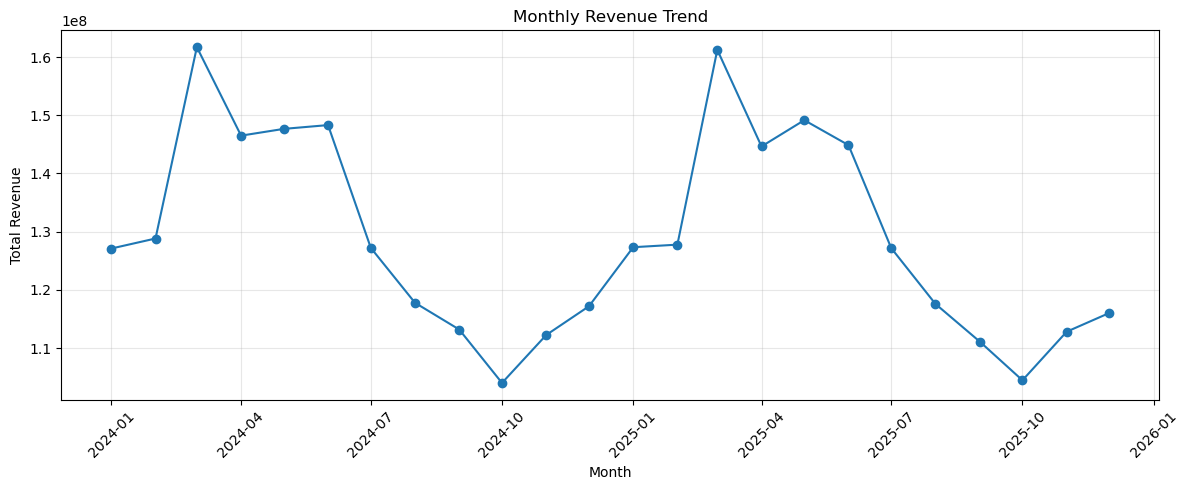

In [238]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Date"], monthly_sales["Total_Revenue"], marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##  Key Findings and Conclusion

The exploration covered sales, inventory, and calendar datasets to establish their structure, data quality, and consistency.

Key findings:
- Sales dataset: 36,550 rows, 6 columns, and 50 unique SKUs.
- Inventory dataset: 4,800 rows, 8 columns, and 200 unique SKUs.
- Calendar dataset: 731 rows, 11 columns, covering 2024–2025.
- Sales and calendar date coverage was consistent.
- A total of 202 sales records had non-positive units sold and were flagged for review.
- A total of 1,370 inventory records had current stock below the reorder point.

Daily and monthly sales summaries were created, and a monthly revenue trend chart was generated.

**Limitations:** This notebook focuses on exploratory analysis and data validation. It does not train predictive models or establish model performance.

**Next step:** Use the validated datasets for downstream customer segmentation, demand forecasting, churn analysis, inventory optimization, and Power BI dashboard development.